<div dir="rtl" style="text-align:right; line-height:2; font-family:Tahoma,sans-serif;">
<h1>ارزیابی Logistic Regression روی داده‌های  نامتوازن</h1>
<h2>Precision–Recall و ROC Curve با دیتاست UCI Online Shoppers</h2>
<p><b>هدف:</b> تحلیل رفتار مدل طبقه‌بندی در مواجهه با داده نامتوازن، بررسی اثر آستانه تصمیم‌گیری و ترسیم PR Curve و ROC Curve.</p>
<p>دیتاست شامل ۱۲٬۳۳۰ جلسه بازدید است که ۱۰٬۴۲۲ جلسه بدون خرید (کلاس صفر) و ۱٬۹۰۸ جلسه منجر به خرید (کلاس یک) هستند. تعداد ویژگی‌های ورودی ۱۷ است.</p>
<p><b>منبع:</b> <a href="https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset">UCI Online Shoppers Purchasing Intention</a></p>
<p><b>توجه:</b> این نوت‌بوک برای بار اول به اینترنت نیاز دارد؛ با اجرای سلول نصب، کتابخانه <code>ucimlrepo</code> نصب می‌شود.</p>
</div>

<div dir="rtl" style="text-align:right;"><h3>۲. بارگذاری دیتاست </h3><p>متغیر <code>Revenue</code> برچسب هدف است: یک یعنی خرید و صفر یعنی بدون خرید.</p></div>

In [2]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# UCI dataset ID = 468
dataset = fetch_ucirepo(id=468)
X = dataset.data.features.copy()
y = dataset.data.targets["Revenue"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget counts:")
print(y.value_counts().sort_index())
print("\nClass ratios (%):")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))
display(X.head())

X shape: (12330, 17)
y shape: (12330,)

Target counts:
Revenue
0    10422
1     1908
Name: count, dtype: int64

Class ratios (%):
Revenue
0    84.53
1    15.47
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True


<div dir="rtl" style="text-align:right;"><h3>۳. تقسیم طبقه‌بندی‌شده Train / Test</h3><p><code>stratify=y</code> سهم کلاس‌های صفر و یک را تقریباً ثابت نگه می‌دارد. مجموعه آزمون برای انتخاب آستانه بهینه استفاده نخواهد شد.</p></div>

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train positive rate:", round(y_train.mean(), 4))
print("Test positive rate:", round(y_test.mean(), 4))

Train: (9864, 17) Test: (2466, 17)
Train positive rate: 0.1547
Test positive rate: 0.1549


<div dir="rtl" style="text-align:right;"><h3>۴. آماده‌سازی ویژگی‌ها و ساخت مدل</h3><p>ستون‌هایی مانند <code>Month</code> و <code>VisitorType</code> و همچنین کدهای <code>Browser</code> و <code>Region</code> دسته‌ای هستند. بنابراین از One-Hot Encoding استفاده می‌کنیم؛ ویژگی‌های عددی با StandardScaler استاندارد می‌شوند. Pipeline همه این عملیات را با یادگیری پارامترها تنها از Train انجام می‌دهد.</p></div>

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_cols = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_cols = [col for col in X.columns if col not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

model.fit(X_train, y_train)
probs = model.predict_proba(X_test)[:, 1]
print("Model trained. Probability array shape:", probs.shape)

Model trained. Probability array shape: (2466,)


<div dir="rtl" style="text-align:right;"><h3>۵. اثر آستانه تصمیم‌گیری</h3><p>برای فهم رفتار مدل، آستانه‌های ۰٫۵، ۰٫۳ و ۰٫۱ را مقایسه می‌کنیم. این یک آزمایش آموزشی روی مجموعه آزمون است؛ از نتایج Test برای تنظیم نهایی مدل استفاده نمی‌کنیم.</p></div>

In [5]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix, classification_report
)

rows = []
for threshold in [0.5, 0.3, 0.1]:
    predictions = (probs >= threshold).astype(int)
    rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_test, predictions),
        "Predicted positives": int(predictions.sum())
    })

display(pd.DataFrame(rows).round(3))
print("Confusion Matrix at threshold 0.5:")
print(confusion_matrix(y_test, (probs >= 0.5).astype(int)))

,Threshold,Precision,Recall,F1,Accuracy,Predicted positives
0,0.5,0.737,0.359,0.482,0.881,186
1,0.3,0.674,0.547,0.604,0.889,310
2,0.1,0.340,0.890,0.492,0.715,1001


Confusion Matrix at threshold 0.5:
[[2035   49]
 [ 245  137]]


<div dir="rtl" style="text-align:right;"><h3>۶. منحنی Precision–Recall و معیار Average Precision</h3><p>در PR Curve محور افقی Recall و محور عمودی Precision است. خط‌چین نشان‌دهنده فراوانی کلاس مثبت در Test است.</p></div>

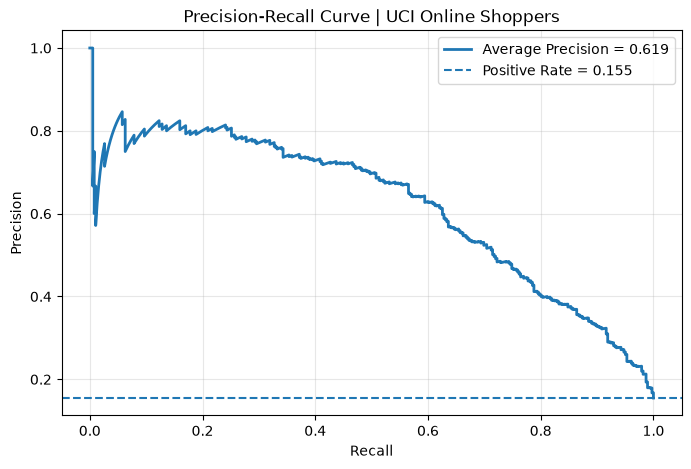

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, pr_thresholds = precision_recall_curve(y_test, probs)
ap = average_precision_score(y_test, probs)
positive_rate = y_test.mean()

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, linewidth=2, label=f"Average Precision = {ap:.3f}")
plt.axhline(y=positive_rate, linestyle="--", label=f"Positive Rate = {positive_rate:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve | UCI Online Shoppers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<div dir="rtl" style="text-align:right;"><h3>۷. منحنی ROC و معیار ROC-AUC</h3><p>در ROC Curve محور افقی False Positive Rate و محور عمودی True Positive Rate است. خط قطر عملکرد رتبه‌بندی تصادفی را نشان می‌دهد.</p></div>

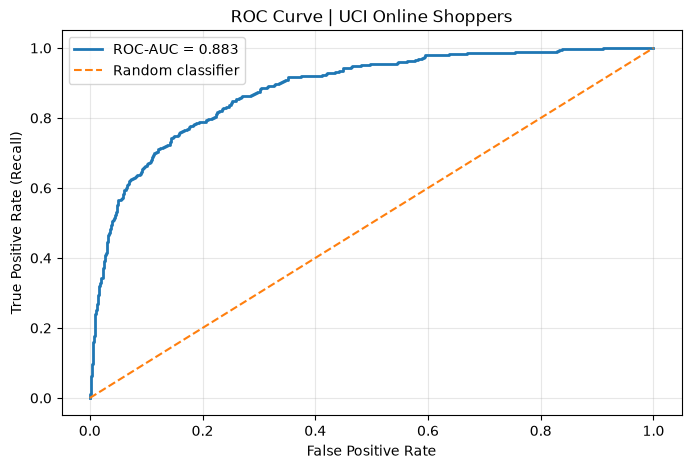

Average Precision (AP): 0.619
ROC-AUC: 0.883


In [7]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(y_test, probs)
roc_auc = roc_auc_score(y_test, probs)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve | UCI Online Shoppers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Average Precision (AP): {ap:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")


<div dir="rtl" style="text-align: right; line-height: 2.2; font-family: Tahoma, sans-serif;">

<h2> تحلیل و نتیجه‌گیری نهایی</h2>

<p>
در این آزمایش، عملکرد الگوریتم
<b>Logistic Regression</b>
برای پیش‌بینی خرید کاربران در مجموعه‌داده نامتوازن
<b>Online Shoppers Purchasing Intention</b>
ارزیابی شد.
</p>

<p>
نتایج نشان داد که مدل با مقدار
<b>ROC-AUC برابر ۰٫۸۸۳</b>
از قدرت تفکیک مناسبی میان دو کلاس برخوردار است.
همچنین مقدار
<b>Average Precision برابر ۰٫۶۱۹</b>
در مقایسه با نرخ پایه کلاس مثبت
<b>(۰٫۱۵۵)</b>،
نشان‌دهنده عملکرد مطلوب مدل در رتبه‌بندی
نمونه‌های مثبت است.
</p>

<h3>🔹 بررسی تأثیر آستانه تصمیم‌گیری</h3>

<p>
بررسی آستانه‌های تصمیم‌گیری نشان داد که در
<b>Threshold برابر ۰٫۵</b>،
مدل Precision معادل
<b>۷۳٫۷٪</b>
و Recall معادل
<b>۳۵٫۹٪</b>
دارد.
</p>

<p>
با کاهش آستانه به
<b>۰٫۳</b>،
مقدار Recall به
<b>۵۴٫۷٪</b>
و F1-score به
<b>۶۰٫۴٪</b>
افزایش یافت؛
درحالی‌که Precision به
<b>۶۷٫۴٪</b>
کاهش پیدا کرد.
</p>

<p>
در آستانه
<b>۰٫۱</b>،
Recall به
<b>۸۹٪</b>
افزایش یافت؛
اما Precision به
<b>۳۴٪</b>
کاهش پیدا کرد که نشان‌دهنده
افزایش قابل‌توجه پیش‌بینی‌های
مثبت اشتباه است.
</p>

<h3>🔹 انتخاب آستانه مناسب</h3>

<p>
در نتیجه،
<b>آستانه ۰٫۳ در میان سه مقدار آزمایش‌شده،
بهترین تعادل را بر اساس معیار F1-score
ایجاد کرده است.</b>
</p>

<p>
بااین‌حال، انتخاب آستانه بهینه
باید بر اساس هدف مسئله،
هزینه خطاها و داده‌های اعتبارسنجی
(Validation Data)
انجام شود.
</p>

<h3>🔹 جمع‌بندی و پیشنهاد برای ادامه پژوهش</h3>

<p>
این آزمایش نشان می‌دهد که تنظیم
آستانه تصمیم‌گیری
<b>(Decision Threshold)</b>
می‌تواند بدون آموزش مجدد مدل،
عملکرد طبقه‌بندی کلاس اقلیت را تغییر دهد.
</p>

<p>
با وجود این، برای بررسی بهبود بیشتر عملکرد،
لازم است روش‌هایی مانند
<b>Class Weight</b>،
<b>Random Oversampling</b>
و
<b>SMOTE</b>
نیز مطالعه و مقایسه شوند.
</p>

<hr>

<p style="color: gray; font-size: 13px;">
<b>نکته پژوهشی:</b>
نتایج این آزمایش می‌توانند به‌عنوان
خط مبنا (Baseline)
برای مقایسه روش‌های مدیریت داده‌های نامتوازن
و بررسی تأثیر آن‌ها بر عملکرد و توضیح‌پذیری
مدل‌های یادگیری ماشین
(Explainable AI)
مورد استفاده قرار گیرند.
</p>

</div>
